### Importing libraries

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
from itables import show

### Importing data

In [44]:
items_processed = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/items_data_processed/high_conf_items_processed_day.csv", sep=";", low_memory=False)
currency_processed = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/currency_data_processed/currency_processed.csv", sep=";", low_memory=False)
basket=pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/items_data_processed/basket.csv", sep=";", low_memory=False)

# Currency Purchasing Power Index 
based on real life CPI: Consumer Price Index

### Items basket

In [3]:
# Adjusting basket dataframe
basket_items = basket["Name"]

basket_prices = items_processed[items_processed["Name"].isin(basket_items)].copy()
basket_prices = basket_prices[["League", "Day", "Name", "Value"]]

basket_prices = basket_prices.rename(columns={"Value": "price_chaos"})
basket_prices

,League,Day,Name,price_chaos
41693,Keepers,1,Heatshiver,10.00
41694,Keepers,2,Heatshiver,27.00
41695,Keepers,3,Heatshiver,11.00
41696,Keepers,4,Heatshiver,7.00
41697,Keepers,5,Heatshiver,8.00
...,...,...,...,...
17261095,Ancestor,37,Starforge,2337.45
17261096,Ancestor,38,Starforge,1778.25
17261097,Ancestor,39,Starforge,933.92
17261098,Ancestor,40,Starforge,910.07


In [4]:
# Price of the entire basket per day and league
basket_price_per_day = (basket_prices.groupby(["League", "Day"])["price_chaos"].sum().reset_index())
basket_price_per_day = basket_price_per_day.rename(columns={"price_chaos": "basket_price"})
basket_price_per_day

,League,Day,basket_price
0,Affliction,1,372.100
1,Affliction,2,2978.970
2,Affliction,3,10296.970
3,Affliction,4,60980.920
4,Affliction,5,73598.155
...,...,...,...
911,Settlers,315,611571.210
912,Settlers,316,594654.730
913,Settlers,317,496280.140
914,Settlers,318,486354.540


In [5]:
# Normalisation realtive to the first day of the league

# price of basket on day 1

day1_prices = (basket_price_per_day[basket_price_per_day["Day"] == 1][["League","basket_price"]].rename(columns={"basket_price":"basket_price_day1"}))
basket_price_per_day = basket_price_per_day.merge(day1_prices,on="League",how="left").copy()

# currency index
basket_price_per_day["currency_index"] = (basket_price_per_day["basket_price"] /basket_price_per_day["basket_price_day1"])
basket_price_per_day = basket_price_per_day[basket_price_per_day["Day"] <= 110].copy()
basket_price_per_day

,League,Day,basket_price,basket_price_day1,currency_index
0,Affliction,1,372.100,372.10,1.000000
1,Affliction,2,2978.970,372.10,8.005832
2,Affliction,3,10296.970,372.10,27.672588
3,Affliction,4,60980.920,372.10,163.883150
4,Affliction,5,73598.155,372.10,197.791333
...,...,...,...,...,...
702,Settlers,106,454477.920,296.16,1534.568882
703,Settlers,107,524225.300,296.16,1770.074622
704,Settlers,108,543615.775,296.16,1835.547593
705,Settlers,109,497425.225,296.16,1679.582742


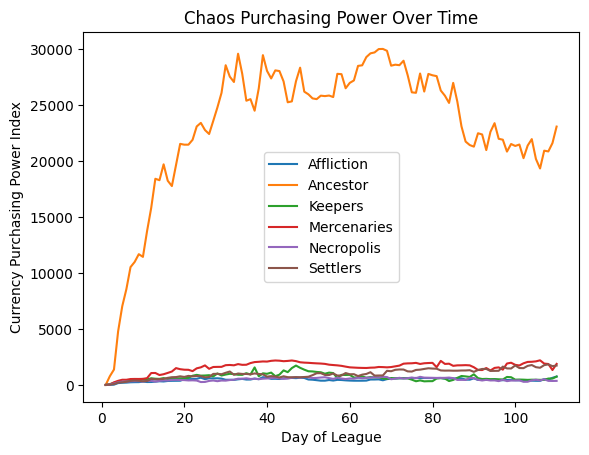

In [ ]:
for league, df_league in basket_price_per_day.groupby("League"):
    plt.plot( df_league["Day"],df_league["currency_index"],label=league)

plt.xlabel("Day of League")
plt.ylabel("Currency Purchasing Power Index")
plt.title("Chaos Purchasing Power Over Time")
plt.legend()

plt.show()

In the early days of a league, many items are not yet traded or appear only later as players progress. This means that the item basket is incomplete on some days, especially at the beginning of the league. Because of this, normalising prices to the first day can produce misleading results. To avoid this problem, the index was calculated using a basket of currencies, which are available every day and actively traded from the start of the league.

### Currency basket

In [71]:
currency_basket = ["Divine Orb","Exalted Orb","Orb of Fusing","Orb of Alchemy","Chromatic Orb","Orb of Alteration","Sacred Orb","Glassblower's Bauble","Cartographer's Chisel","Stacked Deck" "Vaal Orb","Orb of Scouring","Gemcutter's Prism"]

In [ ]:
# add the column "Day" indicates the day of the league

#first day of each league
currency_processed["Date"] = pd.to_datetime(items_processed["Date"])
league_start = currency_processed.groupby("League")["Date"].transform("min")
# league day
currency_processed["Day"] = (currency_processed["Date"]-league_start).dt.days + 1

#exporting dataset
currency_processed.reset_index(drop=True).to_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/currency_data_processed/currency_processed_day.csv",sep=";",index=False)

In [ ]:
# Select currency basket
currency_prices = currency_processed[currency_processed["Get"].isin(currency_basket)].copy()

Currencies in the basket have very different price levels.  **Divine Orb** cost usually hundreds of Chaos Orbs, while other currencies cost only a few Chaos or less than a Chaos. If we averaged the raw prices, expensive currencies would dominate the index and distort the result.

To avoid this, each currency is normalised to its price on the first day of the league. This transforms all currencies to a common relative scale, where the starting value equals 1. As a result, every currency contributes equally to the index, and the indicator reflects relative price changes over time rather than absolute price differences between currencies.

In [ ]:
# Normalise each currency to its Day 1 price
currency_prices["Value_norm"] = (currency_prices["Value"] /currency_prices.groupby(["League", "Get"])["Value"].transform("first"))

,League,Date,Get,Pay,Value,Confidence,Day,Value_norm
0,Keepers,2025-10-31,Chromatic Orb,Chaos Orb,0.20000,High,1,1.000000
1,Keepers,2025-11-01,Chromatic Orb,Chaos Orb,0.19231,High,2,0.961550
2,Keepers,2025-11-02,Chromatic Orb,Chaos Orb,0.19231,High,3,0.961550
3,Keepers,2025-11-03,Chromatic Orb,Chaos Orb,0.16667,High,4,0.833350
4,Keepers,2025-11-04,Chromatic Orb,Chaos Orb,0.14970,High,5,0.748500
...,...,...,...,...,...,...,...,...
150670,Ancestor,2025-12-17,Cartographer's Chisel,Chaos Orb,0.25750,High,48,1.716667
150671,Ancestor,2025-12-18,Cartographer's Chisel,Chaos Orb,0.26005,High,49,1.733667
150672,Ancestor,2025-12-19,Cartographer's Chisel,Chaos Orb,0.26253,High,50,1.750200
150673,Ancestor,2025-12-20,Cartographer's Chisel,Chaos Orb,0.26495,High,51,1.766333


In [ ]:
# Currency CPI (mean of normalised prices per day)
curr_basket_price_per_day = (currency_prices.groupby(["League", "Day"])["Value_norm"].mean().reset_index(name="currency_index"))

#exporting dataset
curr_basket_price_per_day.reset_index(drop=True).to_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/currency_data_processed/currency_index.csv",sep=";",index=False)

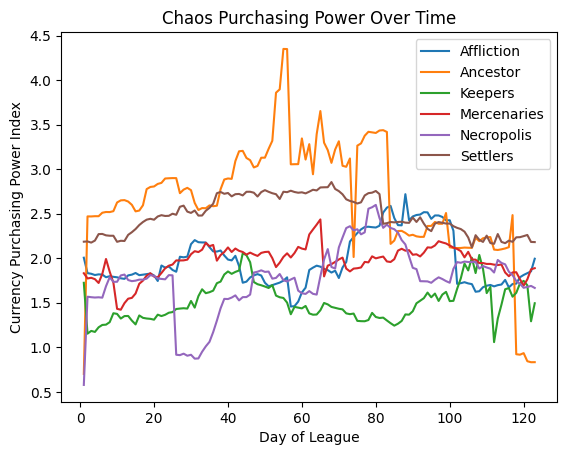

In [ ]:

for league, df_league in curr_basket_price_per_day.groupby("League"):
    plt.plot(df_league["Day"],df_league["currency_index"],label=league)

plt.xlabel("Day of League")
plt.ylabel("Currency Purchasing Power Index")
plt.title("Chaos Purchasing Power Over Time")
plt.legend()
plt.show()
